In [1]:

# =====================================================
# PRACTICA 1: CLUSTERING CON K-MEANS
# Autora: Sandra Yurani Ayala Herrera
# Universidad de Cundinamarca
# =====================================================

# 1. IMPORTACIÓN DE LIBRERÍAS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Librerías importadas correctamente")


Librerías importadas correctamente


In [2]:

# 2. CARGA DEL DATASET WINE

wine = load_wine()

# Crear DataFrame
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Mostrar información general
print("Dimensiones del dataset:", df.shape)

print("\nPrimeras cinco observaciones:")
display(df.head())

print("\nInformación estadística:")
display(df.describe().round(2))

print("\nValores faltantes:")
print(df.isnull().sum().sum())


Dimensiones del dataset: (178, 13)

Primeras cinco observaciones:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Información estadística:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00



Valores faltantes:
0


In [3]:

# =====================================================
# 3. ESTANDARIZACIÓN DE LOS DATOS
# =====================================================

# Separar las variables predictoras
X = df.copy()

# Crear el objeto de estandarización
scaler = StandardScaler()

# Ajustar y transformar los datos
X_scaled = scaler.fit_transform(X)

# Convertir a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Verificar resultados
print("Dimensiones de los datos estandarizados:", X_scaled_df.shape)

print("\nPromedio de las primeras cinco variables:")
print(X_scaled_df.iloc[:, :5].mean().round(4))

print("\nDesviación estándar de las primeras cinco variables:")
print(X_scaled_df.iloc[:, :5].std().round(4))


Dimensiones de los datos estandarizados: (178, 13)

Promedio de las primeras cinco variables:
alcohol             -0.0
malic_acid          -0.0
ash                 -0.0
alcalinity_of_ash   -0.0
magnesium           -0.0
dtype: float64

Desviación estándar de las primeras cinco variables:
alcohol              1.0028
malic_acid           1.0028
ash                  1.0028
alcalinity_of_ash    1.0028
magnesium            1.0028
dtype: float64


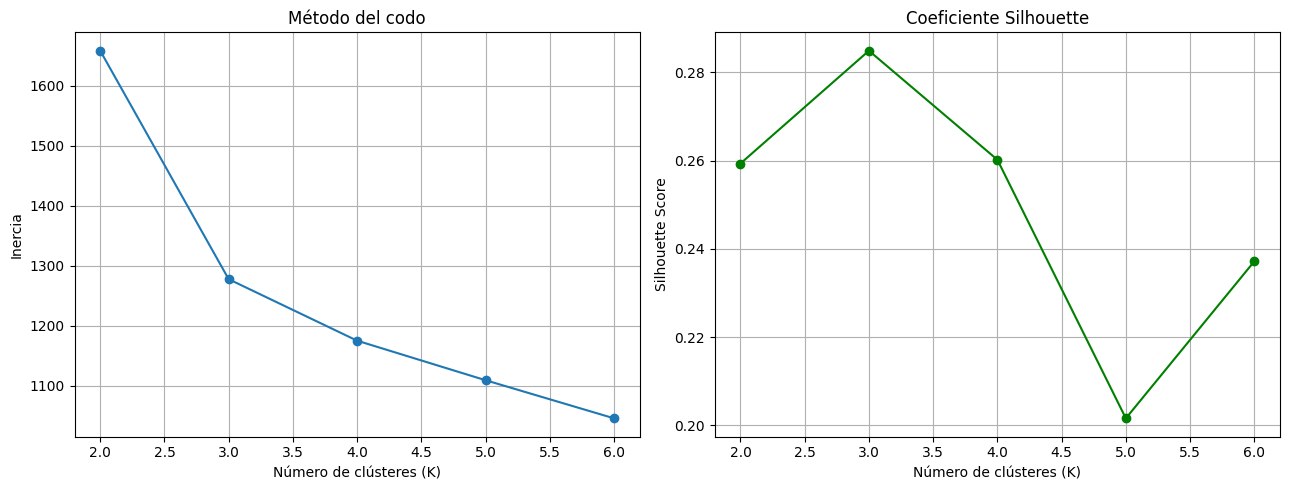

,K,Inercia,Silhouette
0,2,1658.7589,0.2593
1,3,1277.9285,0.2849
2,4,1175.4283,0.2602
3,5,1109.5127,0.2016
4,6,1046.0023,0.2372


In [4]:

# =====================================================
# 4. SELECCIÓN DEL NÚMERO DE CLÚSTERES
# =====================================================

inercias = []
silhouettes = []

valores_k = range(2, 7)

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    inercias.append(modelo.inertia_)

    silhouettes.append(
        silhouette_score(X_scaled, etiquetas)
    )

# Crear gráficas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    list(valores_k),
    inercias,
    marker='o'
)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clústeres (K)")
axes[0].set_ylabel("Inercia")
axes[0].grid(True)

axes[1].plot(
    list(valores_k),
    silhouettes,
    marker='o',
    color='green'
)
axes[1].set_title("Coeficiente Silhouette")
axes[1].set_xlabel("Número de clústeres (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Mostrar resultados
tabla_k = pd.DataFrame({
    "K": list(valores_k),
    "Inercia": inercias,
    "Silhouette": silhouettes
})

display(tabla_k.round(4))


In [5]:

# =====================================================
# 5. MODELO DEFINITIVO K-MEANS
# =====================================================

# Configurar el modelo con 3 clústeres
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Entrenar el modelo y asignar grupos
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Mostrar cantidad de observaciones por grupo
print("Distribución de observaciones por clúster:")
print(df["Cluster"].value_counts().sort_index())

# Calcular métricas de evaluación
silhouette = silhouette_score(
    X_scaled,
    df["Cluster"]
)

davies = davies_bouldin_score(
    X_scaled,
    df["Cluster"]
)

calinski = calinski_harabasz_score(
    X_scaled,
    df["Cluster"]
)

print("\nMÉTRICAS DE EVALUACIÓN K-MEANS")
print("--------------------------------")
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(davies, 4))
print("Calinski-Harabasz Index:", round(calinski, 4))


Distribución de observaciones por clúster:
Cluster
0    65
1    51
2    62
Name: count, dtype: int64

MÉTRICAS DE EVALUACIÓN K-MEANS
--------------------------------
Silhouette Score: 0.2849
Davies-Bouldin Index: 1.3892
Calinski-Harabasz Index: 70.94


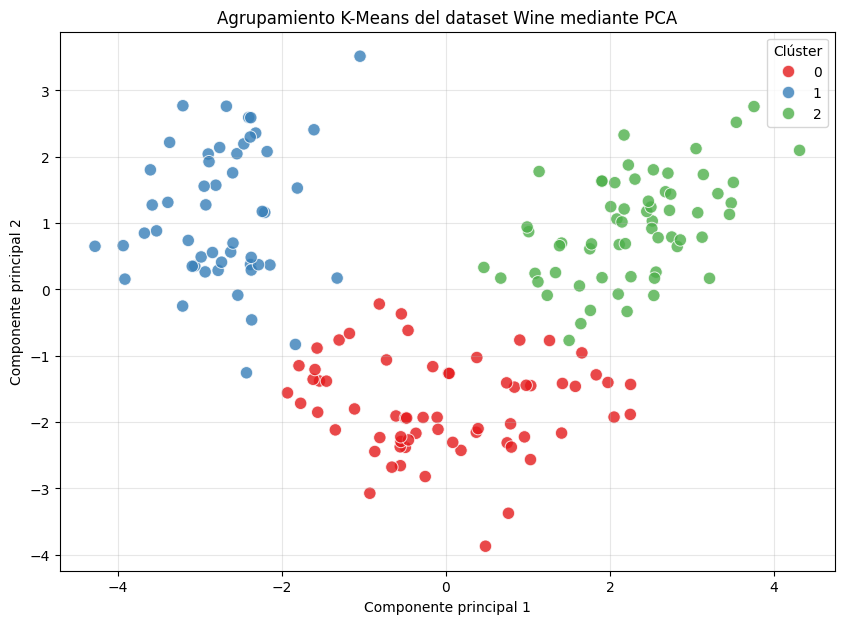

Varianza explicada por las dos componentes: 55.41 %


In [6]:

# =====================================================
# 6. VISUALIZACIÓN DE LOS CLÚSTERES CON PCA
# =====================================================

from sklearn.decomposition import PCA

# Reducir a dos dimensiones para visualizar
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Crear DataFrame para la gráfica
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df["Cluster"]
})

# Graficar agrupaciones
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=80,
    alpha=0.8
)

plt.title("Agrupamiento K-Means del dataset Wine mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Clúster")
plt.grid(alpha=0.3)
plt.show()

print(
    "Varianza explicada por las dos componentes:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [8]:

# RESUMEN FINAL DEL MODELO K-MEANS

print("DISTRIBUCIÓN DE CLÚSTERES")
print(df["Cluster"].value_counts().sort_index())

print("\nMÉTRICAS DE EVALUACIÓN")
print("Silhouette:", round(silhouette, 4))
print("Davies-Bouldin:", round(davies, 4))
print("Calinski-Harabasz:", round(calinski, 4))

print("\nVARIANZA EXPLICADA POR PCA")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


DISTRIBUCIÓN DE CLÚSTERES
Cluster
0    65
1    51
2    62
Name: count, dtype: int64

MÉTRICAS DE EVALUACIÓN
Silhouette: 0.2849
Davies-Bouldin: 1.3892
Calinski-Harabasz: 70.94

VARIANZA EXPLICADA POR PCA
55.41 %


In [9]:

# =====================================================
# PRACTICA 2: CLUSTERING CON DBSCAN
# Autora: Sandra Yurani Ayala Herrera
# Universidad de Cundinamarca
# =====================================================

# 1. IMPORTACIÓN DE LIBRERÍAS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Librerías importadas correctamente")

# =====================================================
# 2. GENERACIÓN DEL DATASET MAKE MOONS
# =====================================================

X, y_real = make_moons(
    n_samples=500,
    noise=0.07,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Variable_X1", "Variable_X2"]
)

print("\nDimensiones del dataset:", df.shape)

print("\nPrimeras cinco observaciones:")
display(df.head())

print("\nValores faltantes:")
print(df.isnull().sum().sum())


Librerías importadas correctamente

Dimensiones del dataset: (500, 2)

Primeras cinco observaciones:


,Variable_X1,Variable_X2
0,0.830622,-0.432614
1,0.740349,0.825196
2,1.033435,-0.489607
3,-0.293316,0.964066
4,0.308208,1.093364



Valores faltantes:
0


In [10]:

# =====================================================
# 4. ESTANDARIZACIÓN DE LOS DATOS
# =====================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Variable_X1", "Variable_X2"]
)

print("Dimensiones de los datos:", X_scaled_df.shape)

print("\nPromedio de las variables:")
print(X_scaled_df.mean().round(4))

print("\nDesviación estándar:")
print(X_scaled_df.std().round(4))


Dimensiones de los datos: (500, 2)

Promedio de las variables:
Variable_X1   -0.0
Variable_X2   -0.0
dtype: float64

Desviación estándar:
Variable_X1    1.001
Variable_X2    1.001
dtype: float64


In [11]:

# =====================================================
# 5. EVALUACIÓN DE PARÁMETROS DBSCAN
# =====================================================

resultados = []

combinaciones = [
    (0.10, 5),
    (0.15, 5),
    (0.20, 5),
    (0.25, 5),
    (0.30, 5),
    (0.20, 10),
    (0.25, 10),
    (0.30, 10)
]

for eps, min_samples in combinaciones:

    modelo = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    etiquetas = modelo.fit_predict(X_scaled)

    # Excluir ruido (-1)
    etiquetas_validas = etiquetas[etiquetas != -1]
    grupos = set(etiquetas_validas)

    n_clusters = len(grupos)
    n_ruido = np.sum(etiquetas == -1)

    # Calcular métricas únicamente si hay
    # al menos dos grupos y más observaciones
    # que grupos para evaluar.

    if n_clusters >= 2 and len(etiquetas_validas) > n_clusters:

        indices = etiquetas != -1

        sil = silhouette_score(
            X_scaled[indices],
            etiquetas[indices]
        )

        db = davies_bouldin_score(
            X_scaled[indices],
            etiquetas[indices]
        )

        ch = calinski_harabasz_score(
            X_scaled[indices],
            etiquetas[indices]
        )

    else:
        sil = np.nan
        db = np.nan
        ch = np.nan

    resultados.append({
        "eps": eps,
        "min_samples": min_samples,
        "Clusters": n_clusters,
        "Ruido": n_ruido,
        "Silhouette": sil,
        "Davies-Bouldin": db,
        "Calinski-Harabasz": ch
    })

tabla_dbscan = pd.DataFrame(resultados)

display(tabla_dbscan.round(4))


,eps,min_samples,Clusters,Ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,0.10,5,24,118,0.4790,0.5432,940.0510
1,0.15,5,4,17,0.1433,1.3355,232.5571
2,0.20,5,2,4,0.3869,1.0179,433.6268
3,0.25,5,2,0,0.3857,1.0215,433.8817
4,0.30,5,2,0,0.3857,1.0215,433.8817
5,0.20,10,2,8,0.3945,0.9993,446.0946
6,0.25,10,2,2,0.3896,1.0120,440.3934
7,0.30,10,2,0,0.3857,1.0215,433.8817


In [12]:

# =====================================================
# 6. MODELO DEFINITIVO DBSCAN
# =====================================================

dbscan = DBSCAN(
    eps=0.20,
    min_samples=10
)

# Entrenar el modelo
etiquetas = dbscan.fit_predict(X_scaled)

# Incorporar las etiquetas al DataFrame
df["Cluster"] = etiquetas

# Distribución de observaciones
print("DISTRIBUCIÓN DE CLÚSTERES")
print(df["Cluster"].value_counts().sort_index())

# Número de grupos y ruido
n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
n_ruido = np.sum(etiquetas == -1)

print("\nNúmero de clústeres:", n_clusters)
print("Observaciones clasificadas como ruido:", n_ruido)
print("Porcentaje de ruido:", round(n_ruido / len(X) * 100, 2), "%")

# Calcular métricas excluyendo ruido
indices = etiquetas != -1

silhouette = silhouette_score(
    X_scaled[indices],
    etiquetas[indices]
)

davies = davies_bouldin_score(
    X_scaled[indices],
    etiquetas[indices]
)

calinski = calinski_harabasz_score(
    X_scaled[indices],
    etiquetas[indices]
)

print("\nMÉTRICAS DE EVALUACIÓN")
print("Silhouette:", round(silhouette, 4))
print("Davies-Bouldin:", round(davies, 4))
print("Calinski-Harabasz:", round(calinski, 4))


DISTRIBUCIÓN DE CLÚSTERES
Cluster
-1      8
 0    244
 1    248
Name: count, dtype: int64

Número de clústeres: 2
Observaciones clasificadas como ruido: 8
Porcentaje de ruido: 1.6 %

MÉTRICAS DE EVALUACIÓN
Silhouette: 0.3945
Davies-Bouldin: 0.9993
Calinski-Harabasz: 446.0946


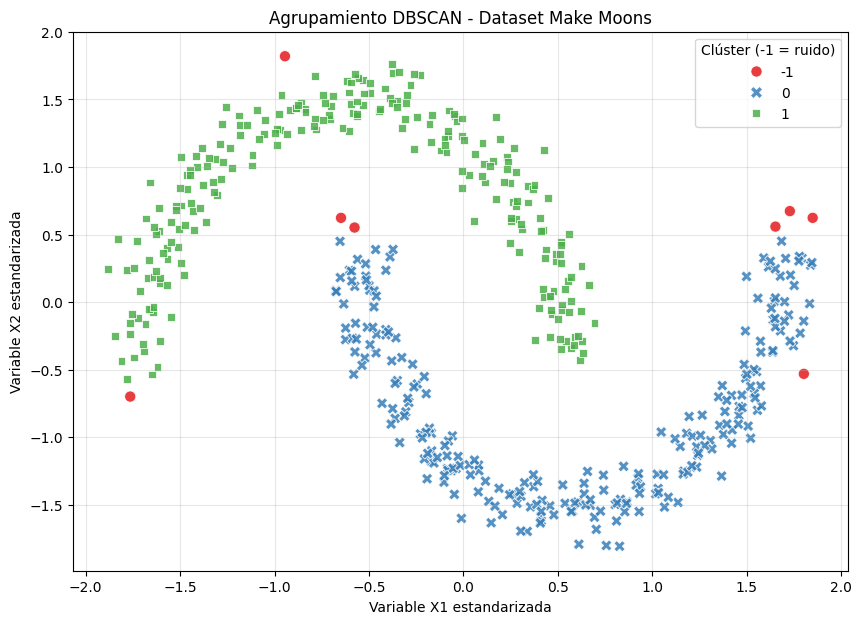

In [13]:

# =====================================================
# 7. VISUALIZACIÓN DE LOS CLÚSTERES DBSCAN
# =====================================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=etiquetas,
    palette="Set1",
    style=etiquetas,
    s=65,
    alpha=0.85
)

plt.title("Agrupamiento DBSCAN - Dataset Make Moons")
plt.xlabel("Variable X1 estandarizada")
plt.ylabel("Variable X2 estandarizada")
plt.legend(title="Clúster (-1 = ruido)")
plt.grid(alpha=0.3)

plt.show()


In [14]:

# =====================================================
# PRACTICA 3: CLUSTERING JERÁRQUICO
# Autora: Sandra Yurani Ayala Herrera
# Universidad de Cundinamarca
# =====================================================

# 1. IMPORTACIÓN DE LIBRERÍAS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

print("Librerías importadas correctamente")

# =====================================================
# 2. CARGA DEL DATASET IRIS
# =====================================================

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("\nDimensiones del dataset:", df.shape)

print("\nPrimeras cinco observaciones:")
display(df.head())

print("\nInformación estadística:")
display(df.describe().round(2))

print("\nValores faltantes:")
print(df.isnull().sum().sum())


Librerías importadas correctamente

Dimensiones del dataset: (150, 4)

Primeras cinco observaciones:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Información estadística:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Valores faltantes:
0


In [15]:

# =====================================================
# 3. ESTANDARIZACIÓN DE LOS DATOS
# =====================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=df.columns
)

print("Dimensiones de los datos estandarizados:")
print(X_scaled_df.shape)

print("\nPromedio de las variables:")
print(X_scaled_df.mean().round(4))

print("\nDesviación estándar de las variables:")
print(X_scaled_df.std().round(4))

display(X_scaled_df.head())


Dimensiones de los datos estandarizados:
(150, 4)

Promedio de las variables:
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64

Desviación estándar de las variables:
sepal length (cm)    1.0034
sepal width (cm)     1.0034
petal length (cm)    1.0034
petal width (cm)     1.0034
dtype: float64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


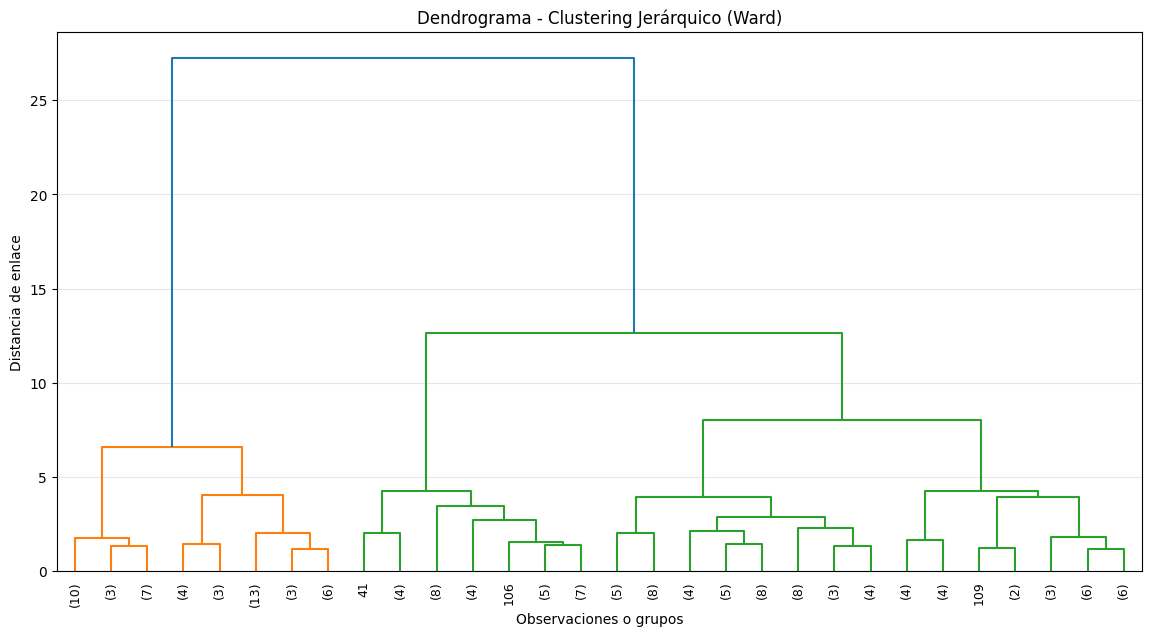

In [16]:

# =====================================================
# 4. CONSTRUCCIÓN DEL DENDROGRAMA
# =====================================================

# Calcular las distancias y agrupaciones jerárquicas
Z = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

# Representar el dendrograma
plt.figure(figsize=(14, 7))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Dendrograma - Clustering Jerárquico (Ward)")
plt.xlabel("Observaciones o grupos")
plt.ylabel("Distancia de enlace")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [17]:

# =====================================================
# 5. COMPARACIÓN DE NÚMERO DE CLÚSTERES
# =====================================================

resultados_jerarquico = []

for k in [2, 3, 4, 5]:

    modelo = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    etiquetas = modelo.fit_predict(X_scaled)

    resultados_jerarquico.append({
        "Clusters": k,
        "Silhouette": silhouette_score(
            X_scaled, etiquetas
        ),
        "Davies-Bouldin": davies_bouldin_score(
            X_scaled, etiquetas
        ),
        "Calinski-Harabasz": calinski_harabasz_score(
            X_scaled, etiquetas
        )
    })

tabla_jerarquico = pd.DataFrame(
    resultados_jerarquico
)

display(tabla_jerarquico.round(4))


,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.5770,0.5917,240.2457
1,3,0.4467,0.8035,222.7192
2,4,0.4006,0.9788,201.2515
3,5,0.3306,0.9742,192.6813


In [18]:

# =====================================================
# 6. MODELO DEFINITIVO DE CLUSTERING JERÁRQUICO
# =====================================================

modelo_jerarquico = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

# Entrenar y obtener las etiquetas
etiquetas_jerarquicas = modelo_jerarquico.fit_predict(
    X_scaled
)

# Incorporar los resultados
df["Cluster"] = etiquetas_jerarquicas

# Distribución de los grupos
print("DISTRIBUCIÓN DE CLÚSTERES")
print(df["Cluster"].value_counts().sort_index())

# Métricas de evaluación
silhouette = silhouette_score(
    X_scaled,
    etiquetas_jerarquicas
)

davies = davies_bouldin_score(
    X_scaled,
    etiquetas_jerarquicas
)

calinski = calinski_harabasz_score(
    X_scaled,
    etiquetas_jerarquicas
)

print("\nMÉTRICAS DE EVALUACIÓN")
print("Silhouette:", round(silhouette, 4))
print("Davies-Bouldin:", round(davies, 4))
print("Calinski-Harabasz:", round(calinski, 4))


DISTRIBUCIÓN DE CLÚSTERES
Cluster
0    101
1     49
Name: count, dtype: int64

MÉTRICAS DE EVALUACIÓN
Silhouette: 0.577
Davies-Bouldin: 0.5917
Calinski-Harabasz: 240.2457


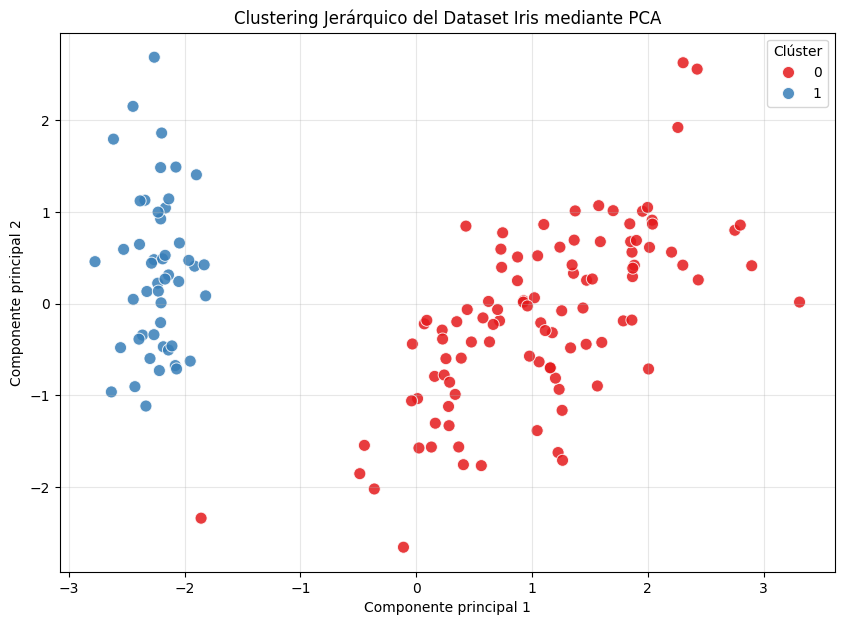


Varianza explicada por las dos componentes: 95.81 %


In [19]:

# =====================================================
# 7. VISUALIZACIÓN MEDIANTE PCA
# =====================================================

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": etiquetas_jerarquicas
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=75,
    alpha=0.85
)

plt.title("Clustering Jerárquico del Dataset Iris mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Clúster")
plt.grid(alpha=0.3)

plt.show()

print(
    "\nVarianza explicada por las dos componentes:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [20]:

# RESUMEN FINAL DEL CLUSTERING JERÁRQUICO

print("DISTRIBUCIÓN DE CLÚSTERES")
print(df["Cluster"].value_counts().sort_index())

print("\nMÉTRICAS DE EVALUACIÓN")
print("Silhouette:", round(silhouette, 4))
print("Davies-Bouldin:", round(davies, 4))
print("Calinski-Harabasz:", round(calinski, 4))

print("\nVARIANZA EXPLICADA POR PCA")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


DISTRIBUCIÓN DE CLÚSTERES
Cluster
0    101
1     49
Name: count, dtype: int64

MÉTRICAS DE EVALUACIÓN
Silhouette: 0.577
Davies-Bouldin: 0.5917
Calinski-Harabasz: 240.2457

VARIANZA EXPLICADA POR PCA
95.81 %
